<a href="https://colab.research.google.com/github/abdulmalik-ade/demo/blob/main/House_price_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 8)

file_path = '/content/dirty_house_price_prediction_dataset.csv'
try:
    df = pd.read_csv(file_path)
    print("Dataset Summary")
    print(f"Shape: {df.shape[0]} rows, {df.shape[1]} columns\n")
except Exception as e:
    print(f"Error loading dataset: {e}")



Dataset Summary
Shape: 512 rows, 10 columns



In [20]:
df.isna().sum()

,0
Property_ID,0
City,0
Location,13
Property_Type,0
Bedrooms,11
Bathrooms,7
Area_sqft,10
Age_Years,10
Parking_Spaces,0
Price_NGN,5


In [21]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Bathrooms,505.0,4.003960,1.997018,1.0,2.0,4.0,6.0,8.0
Age_Years,502.0,15.294821,9.104885,0.0,7.0,15.0,23.0,30.0
Parking_Spaces,512.0,2.054688,1.429675,0.0,1.0,2.0,3.0,4.0


In [22]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 512 entries, 0 to 511
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Property_ID     512 non-null    object 
 1   City            512 non-null    object 
 2   Location        499 non-null    object 
 3   Property_Type   512 non-null    object 
 4   Bedrooms        501 non-null    object 
 5   Bathrooms       505 non-null    float64
 6   Area_sqft       502 non-null    object 
 7   Age_Years       502 non-null    float64
 8   Parking_Spaces  512 non-null    int64  
 9   Price_NGN       507 non-null    object 
dtypes: float64(2), int64(1), object(7)
memory usage: 40.1+ KB


In [23]:
df['Price_NGN'] = pd.to_numeric(df['Price_NGN'], errors='coerce')
df['Area_sqft'] = pd.to_numeric(df['Area_sqft'], errors='coerce')
df['Bedrooms'] = pd.to_numeric(df['Bedrooms'], errors='coerce')
df['Bathrooms'] = pd.to_numeric(df['Bathrooms'], errors='coerce')
df['Age_Years'] = pd.to_numeric(df['Age_Years'], errors='coerce')

df = df.dropna(subset=['Price_NGN'])

print("\n Cleaned Descriptive Statistics")
display(df.describe())


 Cleaned Descriptive Statistics


,Bedrooms,Bathrooms,Area_sqft,Age_Years,Parking_Spaces,Price_NGN
count,482.000000,491.000000,482.000000,489.000000,498.000000,4.980000e+02
mean,3.560166,4.006110,3627.539419,15.349693,2.034137,5.153972e+08
std,1.947735,2.012705,2367.775454,9.157457,1.427257,3.031555e+08
min,1.000000,1.000000,616.000000,0.000000,0.000000,6.391000e+07
25%,2.000000,2.000000,2051.500000,7.000000,1.000000,2.903065e+08
50%,4.000000,4.000000,3415.000000,15.000000,2.000000,4.673900e+08
75%,5.000000,6.000000,4944.250000,23.000000,3.000000,6.575572e+08
max,20.000000,8.000000,32000.000000,30.000000,4.000000,2.200000e+09


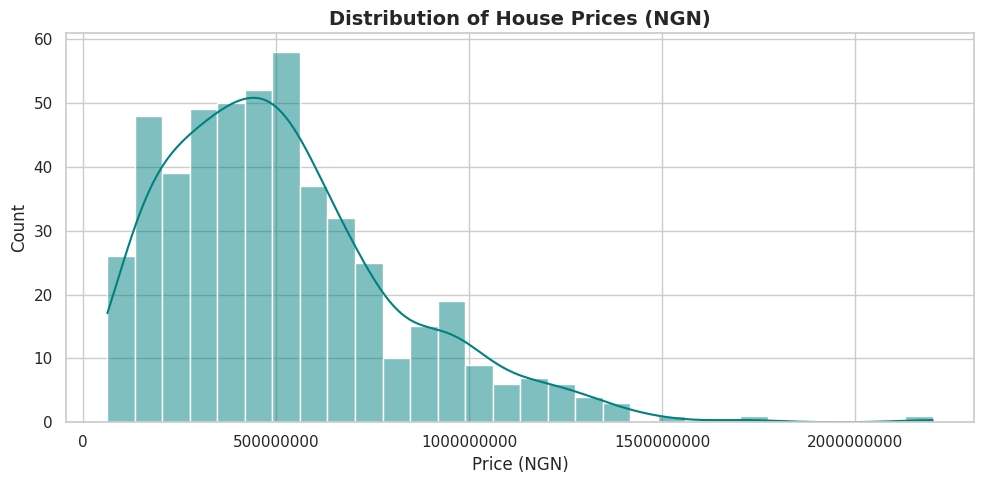

In [24]:

plt.figure(figsize=(10, 5))
sns.histplot(df['Price_NGN'], kde=True, color='teal', bins=30)
plt.title('Distribution of House Prices (NGN)', fontsize=14, fontweight='bold')
plt.xlabel('Price (NGN)', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.ticklabel_format(style='plain', axis='x')
plt.tight_layout()
plt.show()

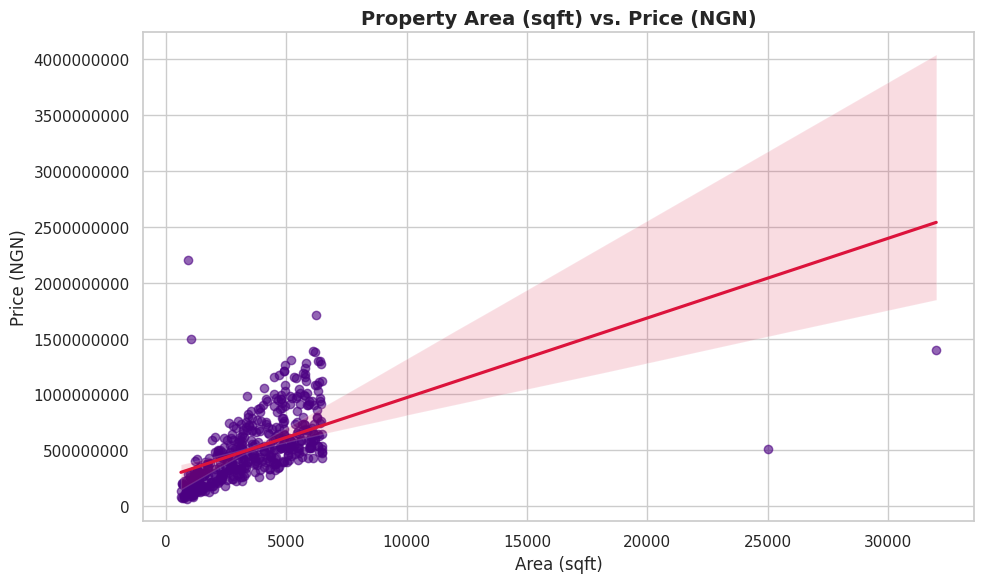

In [25]:
plt.figure(figsize=(10, 6))
sns.regplot(data=df, x='Area_sqft', y='Price_NGN',
            scatter_kws={'alpha':0.6, 'color':'indigo'}, line_kws={'color':'crimson'})
plt.title('Property Area (sqft) vs. Price (NGN)', fontsize=14, fontweight='bold')
plt.xlabel('Area (sqft)', fontsize=12)
plt.ylabel('Price (NGN)', fontsize=12)
plt.ticklabel_format(style='plain', axis='y')
plt.tight_layout()
plt.show()

/tmp/ipykernel_709/479204388.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=avg_price_type, x='Property_Type', y='Price_NGN', palette='viridis')


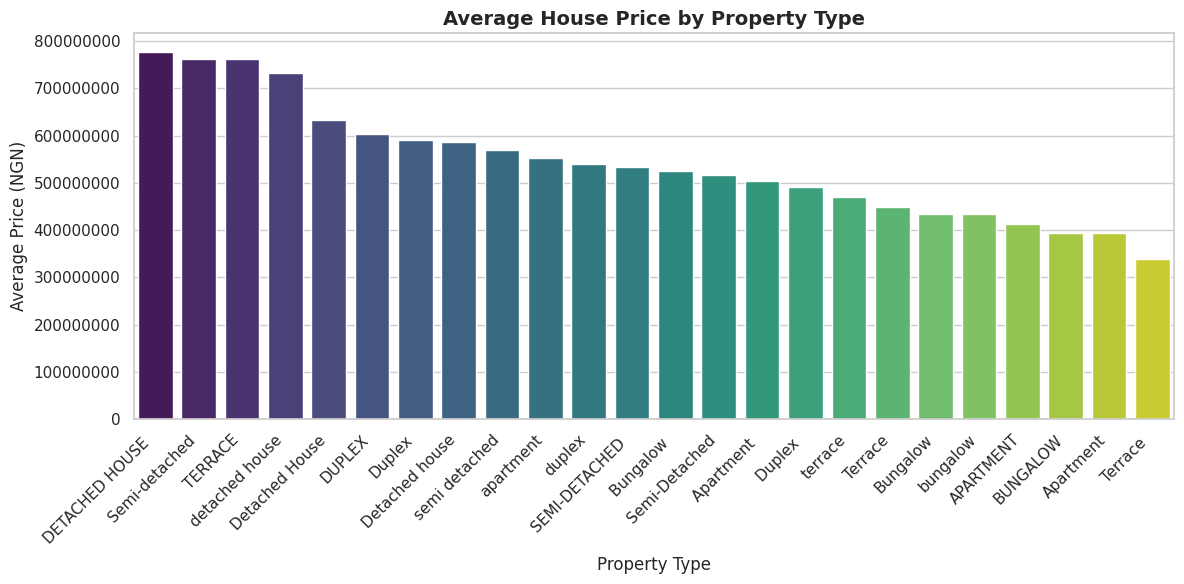

In [26]:
plt.figure(figsize=(12, 6))
avg_price_type = df.groupby('Property_Type')['Price_NGN'].mean().reset_index().sort_values(by='Price_NGN', ascending=False)
sns.barplot(data=avg_price_type, x='Property_Type', y='Price_NGN', palette='viridis')
plt.title('Average House Price by Property Type', fontsize=14, fontweight='bold')
plt.xlabel('Property Type', fontsize=12)
plt.ylabel('Average Price (NGN)', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.ticklabel_format(style='plain', axis='y')
plt.tight_layout()
plt.show()

/tmp/ipykernel_709/4142986665.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_top_cities, x='City', y='Price_NGN', palette='Set2')


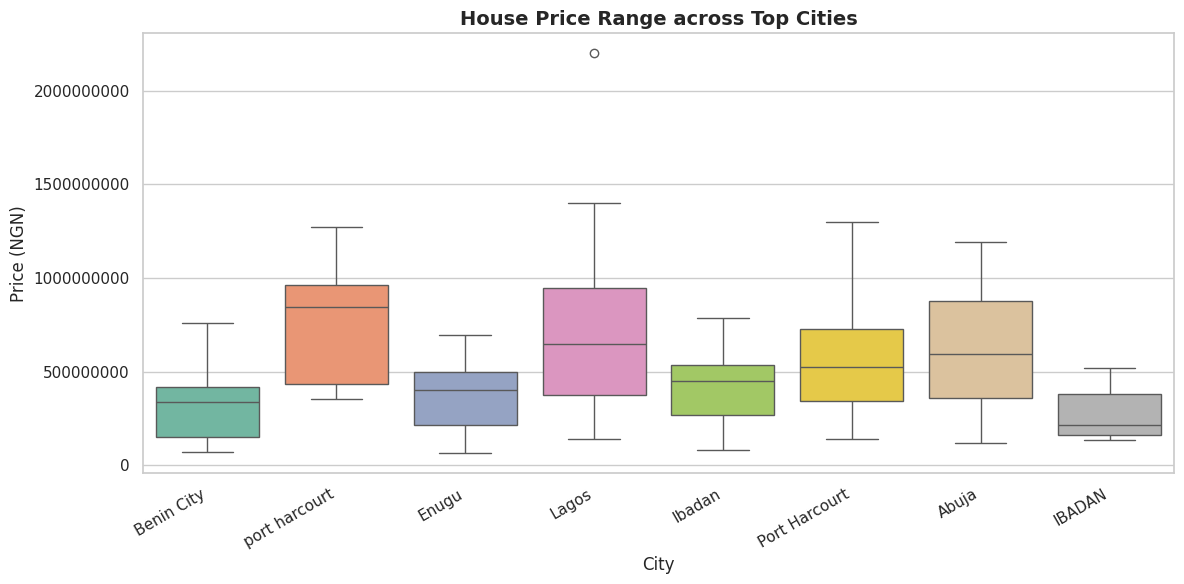

In [27]:
plt.figure(figsize=(12, 6))
top_cities = df['City'].value_counts().nlargest(8).index
df_top_cities = df[df['City'].isin(top_cities)]
sns.boxplot(data=df_top_cities, x='City', y='Price_NGN', palette='Set2')
plt.title('House Price Range across Top Cities', fontsize=14, fontweight='bold')
plt.xlabel('City', fontsize=12)
plt.ylabel('Price (NGN)', fontsize=12)
plt.xticks(rotation=30, ha='right')
plt.ticklabel_format(style='plain', axis='y')
plt.tight_layout()
plt.show()

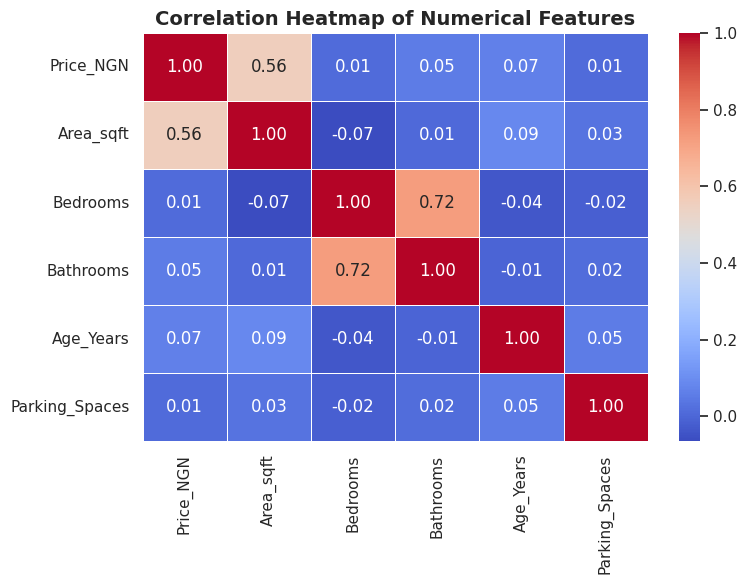

In [28]:
plt.figure(figsize=(8, 6))
numeric_cols = df[['Price_NGN', 'Area_sqft', 'Bedrooms', 'Bathrooms', 'Age_Years', 'Parking_Spaces']]
corr_matrix = numeric_cols.corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Heatmap of Numerical Features', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

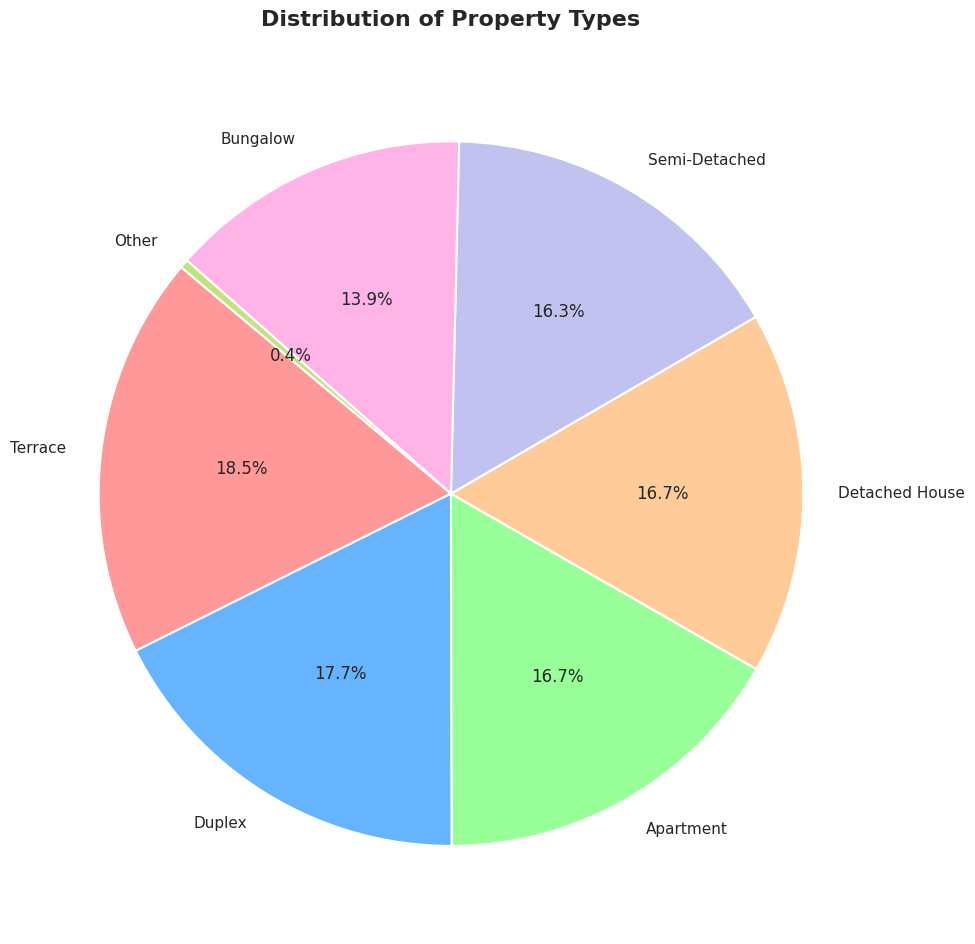

In [30]:
df['Clean_Property_Type'] = df['Property_Type'].astype(str).str.strip().str.title()

property_counts = df['Clean_Property_Type'].value_counts()
threshold = 0.05

if 'Property_Type' in df.columns:
    total_properties = len(df)
    main_properties = property_counts[property_counts / total_properties >= threshold]
    other_properties = property_counts[property_counts / total_properties < threshold]

    if not other_properties.empty:
        main_properties['Other'] = other_properties.sum()

    # Plotting
    plt.figure(figsize=(10, 10))
    colors = ['#ff9999','#66b3ff','#99ff99','#ffcc99','#c2c2f0','#ffb3e6','#c4e17f']

    plt.pie(main_properties,
            labels=main_properties.index,
            autopct='%1.1f%%',
            startangle=140,
            colors=colors[:len(main_properties)],
            wedgeprops={'edgecolor': 'white', 'linewidth': 1.5})

    plt.title('Distribution of Property Types', fontsize=16, fontweight='bold', pad=20)
    plt.tight_layout()
    plt.show()
else:
    print("Column 'Property_Type' was not found in the DataFrame.")